In [20]:
#Organize images into co and tri-culture
import os
import shutil

def organize_files(folder_path):
    """Organizes files into 'Co-culture' or 'Tri-culture' folders based on file names

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the files

    Returns
    -------
    None
    """
    co_culture_folder = os.path.join(folder_path, 'Co-culture')
    tri_culture_folder = os.path.join(folder_path, 'Tri-culture')

    os.makedirs(co_culture_folder, exist_ok=True)
    os.makedirs(tri_culture_folder, exist_ok=True)

    files = os.listdir(folder_path)
    for file in files:
        if file.startswith('Co'):
            shutil.move(os.path.join(folder_path, file), co_culture_folder)
        elif file.startswith('Tri'):
            shutil.move(os.path.join(folder_path, file), tri_culture_folder)


In [21]:
#Specify path to folder of images to be organized into co and tri
organize_files('/Users/allisonpickle/Desktop/Test')

In [ ]:
#Organize images into their magnification
import os
import shutil

def organize_folder_contents(folder_path1, folder_path2):
    """Organizes files in two folders into '5x', '10x', and '20x' folders based on file names

    Parameters
    ----------
    folder_path1 : str
        Path to the first folder containing the files
    folder_path2 : str
        Path to the second folder containing the files

    Returns
    -------
    None
    """
    five_x_folder = os.path.join(folder_path1, '5x')
    ten_x_folder = os.path.join(folder_path1, '10x')
    twenty_x_folder = os.path.join(folder_path1, '20x')

    os.makedirs(five_x_folder, exist_ok=True)
    os.makedirs(ten_x_folder, exist_ok=True)
    os.makedirs(twenty_x_folder, exist_ok=True)

    files1 = os.listdir(folder_path1)
    files2 = os.listdir(folder_path2)
    
    for file in files1:
        if file.endswith('5.czi'):
            shutil.move(os.path.join(folder_path1, file), five_x_folder)
        elif file.endswith('10.czi'):
            shutil.move(os.path.join(folder_path1, file), ten_x_folder)
        elif file.endswith('20.czi'):
            shutil.move(os.path.join(folder_path1, file), twenty_x_folder)
    
    for file in files2:
        if file.endswith('5.czi'):
            shutil.move(os.path.join(folder_path2, file), five_x_folder)
        elif file.endswith('10.czi'):
            shutil.move(os.path.join(folder_path2, file), ten_x_folder)
        elif file.endswith('20.czi'):
            shutil.move(os.path.join(folder_path2, file), twenty_x_folder)


In [18]:
#Organize images into their magnification
import os
import shutil

def organize_folder_contents(folder_path):
    """Organizes files in a folder into '5x', '10x', and '20x' folders based on file names

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the files

    Returns
    -------
    None
    """
    five_x_folder = os.path.join(folder_path, '5x')
    ten_x_folder = os.path.join(folder_path, '10x')
    twenty_x_folder = os.path.join(folder_path, '20x')

    os.makedirs(five_x_folder, exist_ok=True)
    os.makedirs(ten_x_folder, exist_ok=True)
    os.makedirs(twenty_x_folder, exist_ok=True)

    files = os.listdir(folder_path)
    for file in files:
        if file.endswith('5.czi'):
            shutil.move(os.path.join(folder_path, file), five_x_folder)
        elif file.endswith('10.czi'):
            shutil.move(os.path.join(folder_path, file), ten_x_folder)
        elif file.endswith('20.czi'):
            shutil.move(os.path.join(folder_path, file), twenty_x_folder)


In [22]:
#Specify path to organize into their magnification
organize_folder_contents('/Users/allisonpickle/Desktop/Test/Tri-culture')
organize_folder_contents('/Users/allisonpickle/Desktop/Test/Co-culture')

In [23]:
#Turn all czi images into tiff files in new folder "0_Split_Channels"

import os
import sys
import argparse
import numpy as np
import matplotlib.pyplot as plt
from czifile import CziFile
import imageio

def czi_to_tiff(czi_folder):
    """Converts czi files to tiff files

    Parameters
    ----------
    czi_folder : str
        Path to folder containing czi files

    Returns
    -------
    tiff_files : list
        List of tiff files created
    """
    tiff_files = []
    for czi_file in os.listdir(czi_folder):
        if czi_file.endswith('.czi'):
            with CziFile(os.path.join(czi_folder, czi_file)) as czi:
                image_arrays = czi.asarray()
                for channel in range(image_arrays.shape[0]):
                    tiff_file = czi_file.replace('.czi', '_C_{}.tiff'.format(channel))
                    tiff_files.append(tiff_file)
                    tiff_dir = os.path.join(czi_folder, '0_Split_Channels')
                    os.makedirs(tiff_dir, exist_ok=True)
                    # create a folder called Split Channels to store the tiff files within the czi folder
                    imageio.imwrite(os.path.join(tiff_dir, tiff_file), image_arrays[channel, :, :])
 

In [24]:
#Input path to CZI files here
czi_to_tiff('/Users/allisonpickle/Desktop/Test/Co-culture/5x')
czi_to_tiff('/Users/allisonpickle/Desktop/Test/Co-culture/10x')
czi_to_tiff('/Users/allisonpickle/Desktop/Test/Co-culture/20x')

czi_to_tiff('/Users/allisonpickle/Desktop/Test/Tri-culture/5x')
czi_to_tiff('/Users/allisonpickle/Desktop/Test/Tri-culture/10x')
czi_to_tiff('/Users/allisonpickle/Desktop/Test/Tri-culture/20x')

In [30]:
from PIL import Image
import os
import numpy as np
from skimage import restoration

def subtract_background(folder_path):
    """Subtracts background from images in a folder using the rolling ball algorithm

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images

    Returns
    -------
    None
    """
    # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Create a folder to store the result images
    result_folder = os.path.join(folder_path, 'Background_Subtract')
    os.makedirs(result_folder, exist_ok=True)

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Open the image file
        image = Image.open(image_path)

        # Convert the image to a numpy array and cast it to uint16
        image = np.array(image).astype(np.uint16)

        # Perform the desired image processing operations
        background = restoration.rolling_ball(image, radius=50)
        result_image = image - background

        # Save the resulting background-subtracted image to the result folder
        result_image_path = os.path.join(result_folder, image_file)
        result_image = Image.fromarray(result_image)
        result_image.save(result_image_path)


In [32]:
# Specify the folder path containing the images for background subtract
folder_path = '/Users/allisonpickle/Desktop/Test/Co-culture/5x/0_Split_Channels'
subtract_background(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Co-culture/10x/0_Split_Channels'
subtract_background(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Co-culture/20x/0_Split_Channels'
subtract_background(folder_path)

folder_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/5x/0_Split_Channels'
subtract_background(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/10x/0_Split_Channels'
subtract_background(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/20x/0_Split_Channels'
subtract_background(folder_path)

In [98]:
#Apply Scale Bar for 20x Magnification
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar

# Specify the path to the folder containing the TIFF files
folder_path = '/Users/allisonpickle/Desktop/Ctrl 2/0_Split Channels/Background Subtract'

# Get a list of all TIFF files in the folder
tiff_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

# Iterate over each TIFF file
for tiff_file in tiff_files:
    # Construct the full path to the TIFF file
    tiff_path = os.path.join(folder_path, tiff_file)

    # Open the TIFF file
    image = Image.open(tiff_path)

    # Create a figure and axes
    fig, ax = plt.subplots()

    # Display the image
    ax.imshow(image, cmap='gray')

    # Add the scale bar
    scalebar = ScaleBar(0.335, 'um', length_fraction=0.25, color='white', box_color= 'None', location='lower right')
    ax.add_artist(scalebar)

    # Remove the axis labels and ticks
    ax.axis('off')

    # Save the figure with the scale bar
    output_path = os.path.join(folder_path, 'scalebar_' + tiff_file)
    plt.savefig(output_path, bbox_inches='tight', pad_inches=0)

    # Close the figure
    plt.close(fig)


In [37]:
import cv2 
def apply_gaussian_filter(folder_path):
    """Applies a Gaussian low pass filter to images in a folder and saves the filtered images to a new folder called "G_Filter"

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images

    Returns
    -------
    None
    """
    # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Create the output folder "G_Filter" if it doesn't exist
    output_folder = os.path.join(folder_path, "G_Filter")
    os.makedirs(output_folder, exist_ok=True)

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the image
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        # Apply the Gaussian low pass filter
        filtered_image = cv2.GaussianBlur(image, (3, 3), 0)

        # Construct the full path to the output image file
        output_path = os.path.join(output_folder, image_file)

        # Save the filtered image to the output folder
        cv2.imwrite(output_path, filtered_image)
        


In [38]:
folder_path = '/Users/allisonpickle/Desktop/Test/Co-culture/5x/0_Split_Channels/Background_Subtract'
apply_gaussian_filter(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Co-culture/10x/0_Split_Channels/Background_Subtract'
apply_gaussian_filter(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Co-culture/20x/0_Split_Channels/Background_Subtract'
apply_gaussian_filter(folder_path)

folder_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/5x/0_Split_Channels/Background_Subtract'
apply_gaussian_filter(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/10x/0_Split_Channels/Background_Subtract'
apply_gaussian_filter(folder_path)
folder_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/20x/0_Split_Channels/Background_Subtract'
apply_gaussian_filter(folder_path)

In [1]:
#Maybe use for DAPI Channels only
import cv2
import os
import matplotlib.pyplot as plt

def optimize_contrast(folder_path):
    """Optimizes the contrast of TIFF files within a folder and displays the output

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the TIFF files

    Returns
    -------
    None
    """
    # Get a list of all TIFF files in the folder
    tiff_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Iterate over each TIFF file
    for tiff_file in tiff_files:
        # Construct the full path to the TIFF file
        tiff_path = os.path.join(folder_path, tiff_file)

        # Read the TIFF image
        image = cv2.imread(tiff_path, cv2.IMREAD_GRAYSCALE)

        # Apply histogram equalization to optimize the contrast
        equalized_image = cv2.equalizeHist(image)

        # Display the original and optimized images
        fig, axs = plt.subplots(1, 2, figsize=(10, 5))
        axs[0].imshow(image, cmap='gray')
        axs[0].set_title('Original')
        axs[0].axis('off')
        axs[1].imshow(equalized_image, cmap='gray')
        axs[1].set_title('Optimized')
        axs[1].axis('off')
        plt.show()


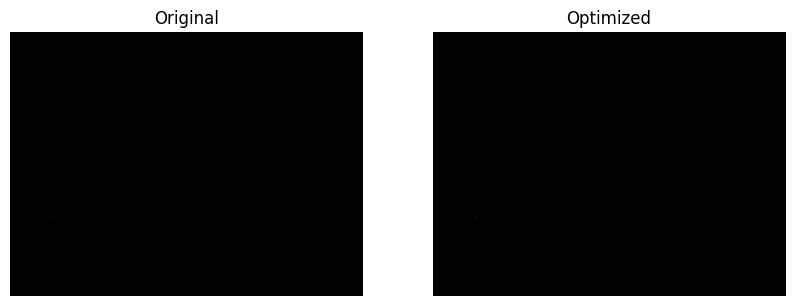

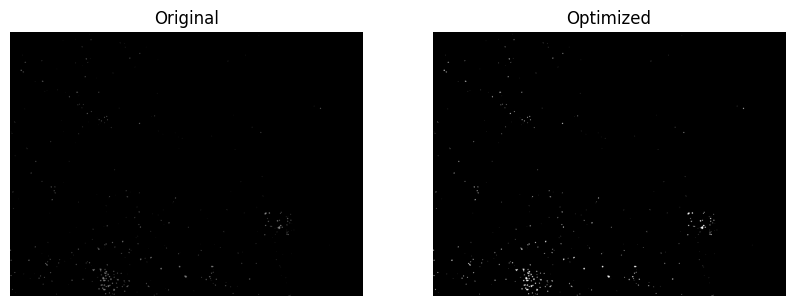

In [2]:
folder_path='/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI'
optimize_contrast(folder_path)


In [4]:
#Adjust contrast of images (visually) via scikit histogram equalization
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from skimage import data, img_as_float
from skimage import exposure


matplotlib.rcParams['font.size'] = 8


def Contrast_Equalization(image, axes, bins=256):
    """Plot an image along with its histogram and cumulative histogram.

    """
    image = img_as_float(image)
    ax_img, ax_hist = axes
    ax_cdf = ax_hist.twinx()



    # Display histogram
    ax_hist.hist(image.ravel(), bins=bins, histtype='step', color='black')
    ax_hist.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
    ax_hist.set_xlabel('Pixel intensity')
    ax_hist.set_xlim(0, 1)
    ax_hist.set_yticks([])

    # Display cumulative distribution
    img_cdf, bins = exposure.cumulative_distribution(image, bins)
    ax_cdf.plot(bins, img_cdf, 'r')
    ax_cdf.set_yticks([])

    return ax_img, ax_hist, ax_cdf


# Load an image from a specified path
image_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI/Tri_Ctrl_6_2_5_C_3.tiff'
img = io.imread(image_path)

# Contrast stretching
p2, p98 = np.percentile(img, (2, 98))
img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))

# Equalization
img_eq = exposure.equalize_hist(img)

# Adaptive Equalization
img_adapteq = exposure.equalize_adapthist(img, clip_limit=0.03)

# Specify the output path for the image
output_path = '/Users/allisonpickle/Desktop/img_eq.tiff'


# Save the image
io.imsave(output_path, img_adapteq)

/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/skimage/_shared/utils.py:316: UserWarning: This might be a color image. The histogram will be computed on the flattened image. You can instead apply this function to each color channel, or set channel_axis.
  return func(*args, **kwargs)


In [77]:
import glob
import os
from skimage import io, exposure


def process_images(folder_path):
    """Process images in a folder by performing contrast stretching, equalization, and adaptive equalization.

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images.

    Returns
    -------
    None
    """
    output_path = '/Users/allisonpickle/Desktop/Test/Co-culture/20x/0_Split_Channels/Background_Subtract/G_Filter/Contrast'

    # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Process each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)
        process_images(image_path)

        # Process the image
        # FILEPATH: /Users/allisonpickle/Library/CloudStorage/Box-Box/0_Şeker Lab/CoPilot/CZI Image Proc.ipynb
        # BEGIN: ed8c6549bwf9
       # img = io.imread(image_path)

        # Contrast stretching
        p2, p98 = np.percentile(img, (2, 98))
        img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))

        # Equalization
        img_eq = exposure.equalize_hist(img)

        # Adaptive Equalization
        import matplotlib.pyplot as plt

        # Load the image
        img = io.imread(output_path)
        # END: ed8c6549bwf9

        # Display the image
        plt.imshow(img, cmap='gray')
        plt.axis('off')
        plt.show()

        # Specify the output path for the image
        output_path = os.path.join(folder_path, 'img_eq.tiff')

        # Save the image
        io.imsave(output_path, img_adapteq)
        # END: be15d9bcejpp


In [79]:
process_images('/Users/allisonpickle/Desktop/Test/Co-culture/20x/0_Split_Channels/Background_Subtract/G_Filter')


NotADirectoryError: [Errno 20] Not a directory: '/Users/allisonpickle/Desktop/Test/Co-culture/20x/0_Split_Channels/Background_Subtract/G_Filter/Co_LPS_2_3_20_C_3.tiff'

In [ ]:
from skimage import io, exposure

def apply_gamma_correction(image_path, gamma, output_path):
    # Load the image
    image = io.imread(image_path)

    # Apply gamma correction
    corrected_image = exposure.adjust_gamma(image, gamma)

    # Save the output image
    io.imsave(output_path, corrected_image)

# Specify the path to save the output image
output_path = "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI/corrected_image.tiff"

# Apply gamma correction and save the output image
apply_gamma_correction(image_path, gamma, output_path)

# Specify the gamma value
gamma = 1.5

# Specify the path to save the output image
input_path = "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI"




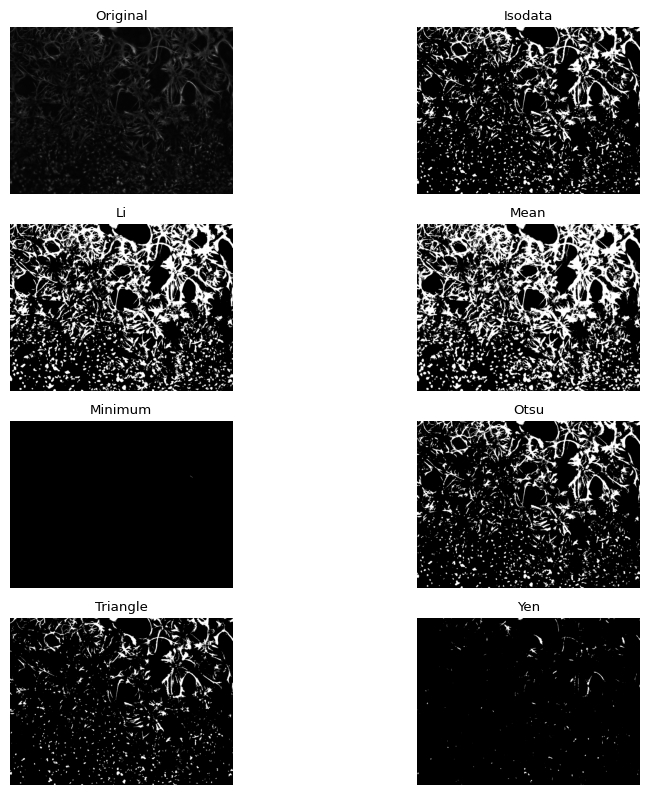

In [6]:
#Test Threshold Options
import os
from skimage import io
from skimage.filters import try_all_threshold
import matplotlib.pyplot as plt

# Specify the folder path containing the images
folder_path = '/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes'

# Get a list of all image files in the folder
image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

# Iterate over each image file
for image_file in image_files:
    # Construct the full path to the image file
    image_path = os.path.join(folder_path, image_file)

    # Read the image
    img = io.imread(image_path)

    # Apply the try_all_threshold function
    fig, ax = try_all_threshold(img, figsize=(10, 8), verbose=False)
    plt.show()
